In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import neo

%matplotlib inline
mpl.rcParams['font.size']    = 8.0
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family']  = 'Arial'

In [2]:
project_root = os.getcwd()

os.chdir('./dataFolder/load_intan_rhd_format/')

if 'load_intan_rhd_format' in sys.modules:
    del sys.modules['load_intan_rhd_format']
if 'intanutil' in sys.modules:
    del sys.modules['intanutil']
from load_intan_rhd_format import read_data
os.chdir(project_root)


print('read_data loaded OK:', read_data)
print('cwd:', os.getcwd())

read_data loaded OK: <function read_data at 0x12fa83380>
cwd: /Users/meghnaanand/Desktop/PiliferAnalysis


In [27]:
rhd_path = './dataFolder/1_RHD_Files/m30_wn1.rhd'
out_path = './dataFolder/Figures/Waveforms'
print(f'Loading {rhd_path} ...')
result = read_data(rhd_path)
print('\nKeys in result dict:')
print(list(result.keys()))

Loading ./dataFolder/1_RHD_Files/m30_wn1.rhd ...

Reading Intan Technologies RHD Data File, Version 1.5

Found 16 amplifier channels.
Found 0 auxiliary input channels.
Found 0 supply voltage channels.
Found 1 board ADC channel.
Found 1 board digital input channel.
Found 0 board digital output channels.
Found 0 temperature sensors channels.

File contains 361.920 seconds of data.  Amplifiers were sampled at 30.00 kS/s.

Allocating memory for data...
Reading data from file...
10% done...
20% done...
30% done...
40% done...
50% done...
60% done...
70% done...
80% done...
90% done...
Parsing data...
Done!  Elapsed time: 9.8 seconds

Keys in result dict:
['spike_triggers', 'amplifier_channels', 'notes', 'frequency_parameters', 'board_adc_channels', 'board_dig_in_channels', 't_amplifier', 'amplifier_data', 't_board_adc', 'board_adc_data', 't_dig', 'board_dig_in_data']


In [28]:
moth_to_channel = {
    'm11_wn2': 'A-015',
    'm23_wn2': 'A-001',
    'm29_wn2': 'A-027',
    'm30_wn1': 'A-007',
    'm31_wn2': 'A-029',}

In [29]:
moth     = 'm30_wn1'
unit_id  = 1                                              # the unit- whichever i want 
Fs       = 30000
window_ms = (-1.5, 2.0)                                            # -1ms before spike to +2ms after- can edit this
pre_samples  = int(abs(window_ms[0]) * Fs / 1000)                  # 30 samples before
post_samples = int(window_ms[1] * Fs / 1000)                       # 60 samples after
total_samples = pre_samples + post_samples                         # 90 samples = 3 ms


spike_files = {
    'm11_wn2': './dataFolder/2_Spikesorted_Files/m11_wn2_15.txt',
    'm23_wn2': './dataFolder/2_Spikesorted_Files/m23_wn2_01.txt',
    'm29_wn2': './dataFolder/2_Spikesorted_Files/m29_wn2_12.txt',
    'm30_wn1': './dataFolder/2_Spikesorted_Files/m30_wn1_07.txt',
    'm31_wn2': './dataFolder/2_Spikesorted_Files/m31_wn2_14.txt',}

T = pd.read_csv(spike_files[moth], delimiter=r'\s+')
print(f'total spikes in file: {len(T)}, units present: {sorted(T["Unit"].unique())}')

# takes only spikes of unit ID- (can make a run through all)
spike_times_s = T.loc[T['Unit'] == unit_id, 'Timestamp'].values
print(f'unit {unit_id}: {len(spike_times_s)} spikes')

# find the right voltage channel
target = moth_to_channel[moth]
ch_idx = next(i for i, ch in enumerate(result['amplifier_channels']) 
              if ch['native_channel_name'] == target)
print(f'using channel {target} (Python index {ch_idx})')

voltage = result['amplifier_data'][ch_idx]
print(f'voltage trace length: {len(voltage)} samples = {len(voltage)/Fs:.1f} s')

# convert spike times to sample indices, extract snippets
spike_idx = (spike_times_s * Fs).astype(int)
snippets = []
for s in spike_idx:
    start = s - pre_samples
    stop  = s + post_samples
    if start < 0 or stop > len(voltage):
        continue                                                   # skip spikes too close to recording edges
    snippets.append(voltage[start:stop])
snippets = np.array(snippets)
print(f'extracted {len(snippets)} waveform snippets, shape: {snippets.shape}')

total spikes in file: 23325, units present: [np.int64(0), np.int64(1), np.int64(2)]
unit 1: 10310 spikes
using channel A-007 (Python index 7)
voltage trace length: 10857600 samples = 361.9 s
extracted 10310 waveform snippets, shape: (10310, 105)


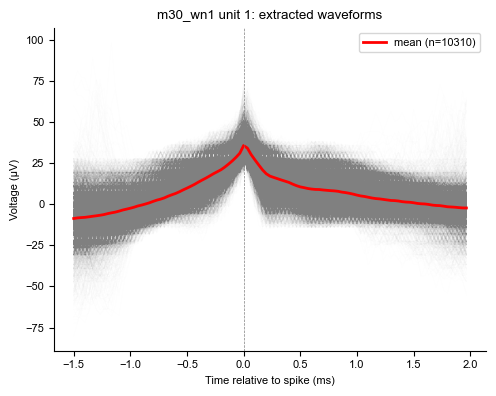

In [30]:
t_ms = np.arange(-pre_samples, post_samples) / Fs * 1000

fig, ax = plt.subplots(figsize=(5, 4))

# all individual spikes, faint
for snip in snippets:
    ax.plot(t_ms, snip, color='gray', alpha=0.01, linewidth=0.5)

mean_wf = snippets.mean(axis=0)
ax.plot(t_ms, mean_wf, color='red', linewidth=2, label=f'mean (n={len(snippets)})')

ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax.set_xlabel('Time relative to spike (ms)')
ax.set_ylabel('Voltage (µV)')
ax.set_title(f'{moth} unit {unit_id}: extracted waveforms')
ax.legend(fontsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
out_fig = './dataFolder/Figures/SpikeWaveformCheck/'
os.makedirs(out_fig, exist_ok=True)

fig.savefig(out_fig + f'{moth}_unit_{unit_id}_waveforms.pdf', bbox_inches='tight')
plt.show()


spike #5000 at t=146.7406 s


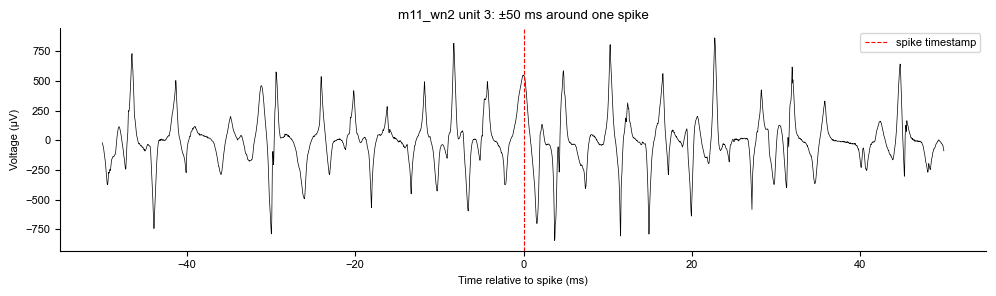

In [47]:
example_spike_s = spike_times_s[100]
print(f'spike #5000 at t={example_spike_s:.4f} s')

window_ms_wide = 50
start = int((example_spike_s - window_ms_wide/1000) * Fs)
stop  = int((example_spike_s + window_ms_wide/1000) * Fs)
t_wide  = (np.arange(start, stop) / Fs - example_spike_s) * 1000
v_wide  = voltage[start:stop]

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t_wide, v_wide, color='black', linewidth=0.5)
ax.axvline(0, color='red', linestyle='--', linewidth=0.8, label='spike timestamp')
ax.set_xlabel('Time relative to spike (ms)')
ax.set_ylabel('Voltage (µV)')
ax.set_title(f'{moth} unit {unit_id}: ±{window_ms_wide} ms around one spike')
ax.legend(fontsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
# print('amplifier_data shape:', result['amplifier_data'].shape)
# print('amplifier sample rate:', result['frequency_parameters']['amplifier_sample_rate'])
# print('\nAmplifier channels:')
# for i, ch in enumerate(result['amplifier_channels']):
#     print(f'  index {i}: native={ch["native_channel_name"]}, custom={ch.get("custom_channel_name", "")}')